### Resampling data and plotting it with pandas and Matplotlib 

We did our first data analysis with a large data set and saw how we could answer a research question based on a simple categorization. Although it produced good results, that sort of analysis is limited: it looks at the data at only one point in time. Analyzing data across time, on the other hand, allows us to look for trends and better understand the anomalies we encounter. By exploring the changes in data and isolating specific events, we can make meaningful connections between them. 

This data on evictions in New York was [downloaded from the NYC Open Portal site](https://data.cityofnewyork.us/City-Government/Evictions/6z8x-wfk4/about_data).

Here are the steps we need to take:
- Filter our data using a lambda function
- Format a data column into a datetime 
- Use the resample function
- plot the data with matplotlib


Let's start by important `pandas` and `matplotlib` (`import matplotlib.pyplot as plt`):

In [2]:
%pip install matplotlib

  Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl.metadata (80 kB)
  Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl.metadata (3.8 kB)
  Using cached cycler-0.12.1-py3-none-any.whl.metadata (3.8 kB)
  Using cached fonttools-4.67.0-cp314-cp314-macosx_10_15_universal2.whl.metadata (137 kB)
  Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl.metadata (5.2 kB)
  Using cached pyparsing-3.3.3-py3-none-any.whl.metadata (5.9 kB)
Using cached matplotlib-3.11.2-cp314-cp314-macosx_11_0_arm64.whl (9.3 MB)
Using cached contourpy-1.4.0-cp314-cp314-macosx_11_0_arm64.whl (283 kB)
Using cached cycler-0.12.1-py3-none-any.whl (8.3 kB)
Using cached fonttools-4.67.0-cp314-cp314-macosx_10_15_universal2.whl (3.1 MB)
Using cached kiwisolver-1.5.1-cp314-cp314-macosx_11_0_arm64.whl (64 kB)
Using cached pyparsing-3.3.3-py3-none-any.whl (126 kB)
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 6/6 [matplotlib]6 [matplotlib]
Note: you may need to restart the kernel to use u

In [3]:
import pandas as pd
import matplotlib.pyplot as plt

Matplotlib is building the font cache; this may take a moment.


Read in the csv file with the evictions data:

In [4]:
%%time
evictions = pd.read_csv('../data/Evictions_20240615.csv')

CPU times: user 108 ms, sys: 12.6 ms, total: 120 ms
Wall time: 130 ms


In [3]:
evictions.head()

,Court Index Number,Docket Number,Eviction Address,Eviction Apartment Number,Executed Date,Marshal First Name,Marshal Last Name,Residential/Commercial,BOROUGH,Eviction Postcode,Ejectment,Eviction/Legal Possession,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA
0,318594/23,14150,172 WEST 107TH ST,1W,01/04/2024,David,Smith,Residential,MANHATTAN,10025,Not an Ejectment,Possession,40.800704,-73.964267,7.0,7.0,193.0,1055977.0,1.018610e+09,Morningside Heights
1,016134/18,86658,70 BRUCKNER BLVD.,12E,11/29/2018,Henry,Daley,Residential,BRONX,10454,Not an Ejectment,Possession,40.806321,-73.926264,1.0,8.0,19.0,2116953.0,2.022950e+09,Mott Haven-Port Morris
2,300816/222,209993,23 WYONA STREET,NaN,11/30/2022,Richard,Capuano,Residential,QUEENS,11207,Not an Ejectment,Possession,40.678696,-73.894650,5.0,37.0,1146.0,3389505.0,3.036630e+09,Cypress Hills-City Line
3,K52673/17,94663,601 BRIGHTON BEACH A VE,FRONT GROUND STORE,04/12/2017,Darlene,Barone,Commercial,BROOKLYN,11235,Not an Ejectment,Possession,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,79638/19,173756,540 NEW LOTS AVE,1R,01/18/2024,Alfred,Locascio,Residential,BROOKLYN,11207,Not an Ejectment,Possession,40.663958,-73.888289,5.0,42.0,1122.0,3096753.0,3.043040e+09,East New York (Pennsylvania Ave)


In [5]:
evictions.dtypes

Court Index Number               str
Docket Number                  int64
Eviction Address                 str
Eviction Apartment Number        str
Executed Date                    str
Marshal First Name               str
Marshal Last Name                str
Residential/Commercial           str
BOROUGH                          str
Eviction Postcode              int64
Ejectment                        str
Eviction/Legal Possession        str
Latitude                     float64
Longitude                    float64
Community Board              float64
Council District             float64
Census Tract                 float64
BIN                          float64
BBL                          float64
NTA                              str
dtype: object

In [6]:
evictions['BOROUGH'].value_counts()

BOROUGH
BRONX            29264
BROOKLYN         26830
QUEENS           17803
MANHATTAN        15189
STATEN ISLAND     3428
Name: count, dtype: int64

### Resampling our data over time

To get a tally of these tweets over time we need to:
- format a column as a date time
- set the index of our dataframe to this date time column
- resample our dataframe 

In [7]:
evictions.dtypes

Court Index Number               str
Docket Number                  int64
Eviction Address                 str
Eviction Apartment Number        str
Executed Date                    str
Marshal First Name               str
Marshal Last Name                str
Residential/Commercial           str
BOROUGH                          str
Eviction Postcode              int64
Ejectment                        str
Eviction/Legal Possession        str
Latitude                     float64
Longitude                    float64
Community Board              float64
Council District             float64
Census Tract                 float64
BIN                          float64
BBL                          float64
NTA                              str
dtype: object

In [8]:
evictions['Executed Date'] = evictions['Executed Date'].astype('datetime64[ns]')

In [9]:
evictions.dtypes

Court Index Number                      str
Docket Number                         int64
Eviction Address                        str
Eviction Apartment Number               str
Executed Date                datetime64[ns]
Marshal First Name                      str
Marshal Last Name                       str
Residential/Commercial                  str
BOROUGH                                 str
Eviction Postcode                     int64
Ejectment                               str
Eviction/Legal Possession               str
Latitude                            float64
Longitude                           float64
Community Board                     float64
Council District                    float64
Census Tract                        float64
BIN                                 float64
BBL                                 float64
NTA                                     str
dtype: object

In [ ]:
# This creates a new DataFrame called evictions_over_time, using Executed Date as its index.
# An index is what pandas uses to label and organize rows. By default, pandas assigns row numbers such as 0, 1, and 2. 
# Why is this useful? A datetime index allows pandas to perform time-based operations, such as counting evictions by month.

evictions_over_time = evictions.set_index('Executed Date')

# Check that the data loaded correctly. The dates look right. Executed Date is now the index. The other columns are still present.
evictions_over_time.head()

,Court Index Number,Docket Number,Eviction Address,Eviction Apartment Number,Marshal First Name,Marshal Last Name,Residential/Commercial,BOROUGH,Eviction Postcode,Ejectment,Eviction/Legal Possession,Latitude,Longitude,Community Board,Council District,Census Tract,BIN,BBL,NTA
Executed Date,,,,,,,,,,,,,,,,,,,
2024-01-04,318594/23,14150,172 WEST 107TH ST,1W,David,Smith,Residential,MANHATTAN,10025,Not an Ejectment,Possession,40.800704,-73.964267,7.0,7.0,193.0,1055977.0,1.018610e+09,Morningside Heights
2018-11-29,016134/18,86658,70 BRUCKNER BLVD.,12E,Henry,Daley,Residential,BRONX,10454,Not an Ejectment,Possession,40.806321,-73.926264,1.0,8.0,19.0,2116953.0,2.022950e+09,Mott Haven-Port Morris
2022-11-30,300816/222,209993,23 WYONA STREET,NaN,Richard,Capuano,Residential,QUEENS,11207,Not an Ejectment,Possession,40.678696,-73.894650,5.0,37.0,1146.0,3389505.0,3.036630e+09,Cypress Hills-City Line
2017-04-12,K52673/17,94663,601 BRIGHTON BEACH A VE,FRONT GROUND STORE,Darlene,Barone,Commercial,BROOKLYN,11235,Not an Ejectment,Possession,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2024-01-18,79638/19,173756,540 NEW LOTS AVE,1R,Alfred,Locascio,Residential,BROOKLYN,11207,Not an Ejectment,Possession,40.663958,-73.888289,5.0,42.0,1122.0,3096753.0,3.043040e+09,East New York (Pennsylvania Ave)


In [13]:
# Resampling in pandas is a powerful method used to control the reporting frequency of time-series data.
# Groups rows into monthly time intervals, using the datetime index.
# Selects the court index number column from those monthly groups.
# Counts the non-null values in that column for each month. It doesn't count empty or missing values.
# Saves the resulting monthly counts in a new variable called evictions_tally.

evictions_tally = evictions_over_time.resample('ME')["Court Index Number"].count()
evictions_tally.head()

Executed Date
2017-01-31    2237
2017-02-28    1695
2017-03-31    2040
2017-04-30    1860
2017-05-31    2080
Freq: ME, Name: Court Index Number, dtype: int64

### Plot your data 

Now it's time to plot your data to better understand trends over time!

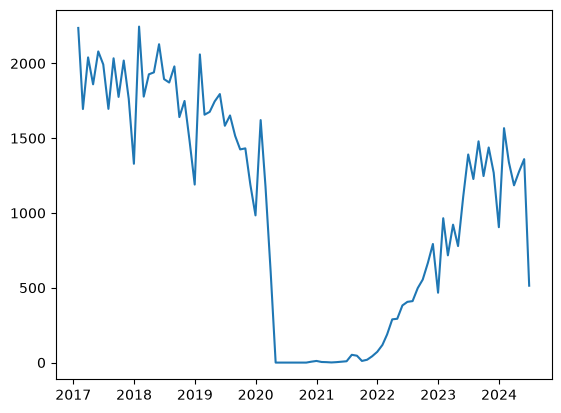

In [ ]:
plt.plot(evictions_tally)

In [15]:
len(evictions_tally)

90

In [16]:
len(evictions)

92514

### Modifying your chart

First, there are so many ways to do the same thing:

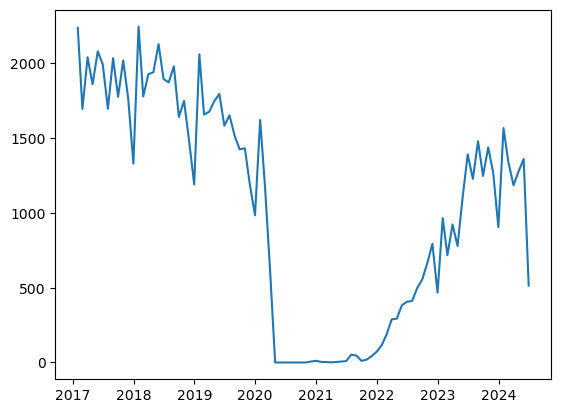

In [14]:
plt.plot(evictions_tally)

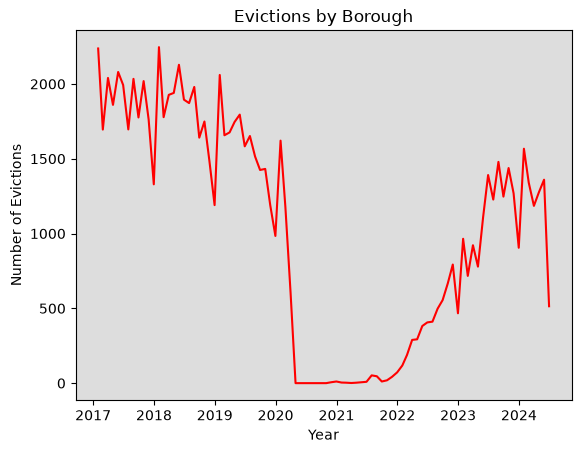

In [34]:
# Create a figure containing a single axes (using a different function)
fig, ax = plt.subplots()

ax.plot(evictions_tally, color="red")
ax.set_title("Evictions by Borough")
ax.set_xlabel("Year")
ax.set_ylabel("Number of Evictions")
ax.set_facecolor('#ddd')

plt.show()

<Axes: xlabel='Executed Date'>

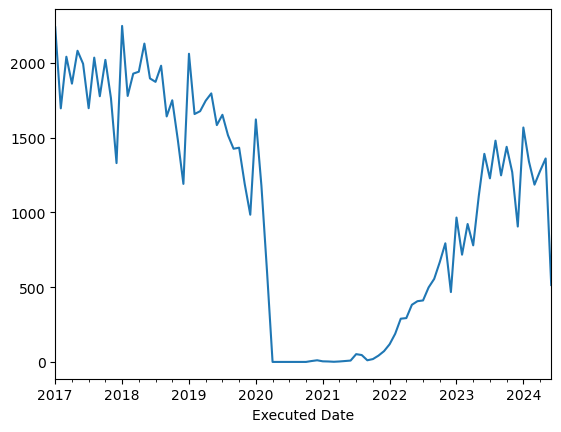

In [16]:
evictions_tally.plot()

#### Labeling your charts

#### Changing the size of your chart

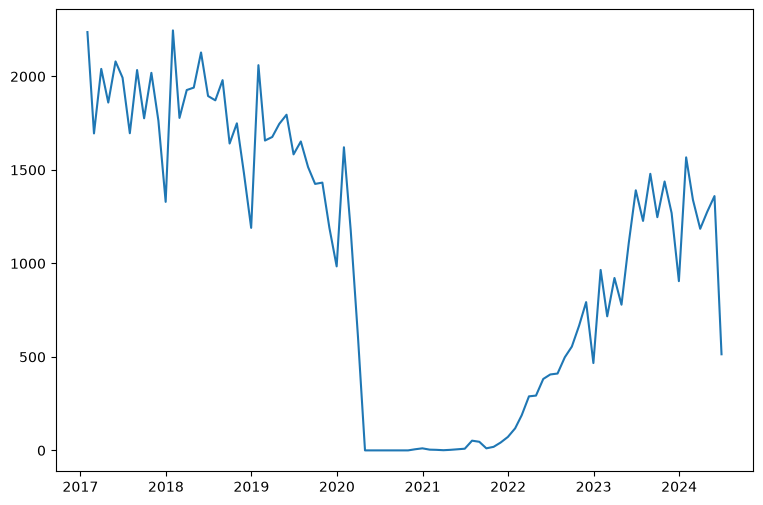

In [18]:
fig, ax = plt.subplots()
fig.set_size_inches(9,6)
ax.plot(evictions_tally)


#### Other chart types

##### Bar Charts

In [ ]:
# In pandas, .reset_index() turns the existing index into a regular column and replaces it with a default numbered index (0, 1, 2, 3, ...).

ranked_boroughs = evictions["BOROUGH"].value_counts().reset_index()

print(len(ranked_boroughs))
ranked_boroughs

5


,BOROUGH,count
0,BRONX,29264
1,BROOKLYN,26830
2,QUEENS,17803
3,MANHATTAN,15189
4,STATEN ISLAND,3428


<Axes: ylabel='BOROUGH'>

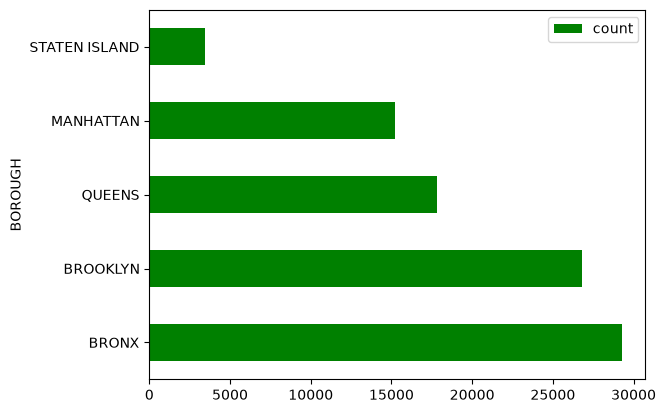

In [38]:
ranked_boroughs.plot(x="BOROUGH", y="count", kind="barh", color="green")


##### pie charts

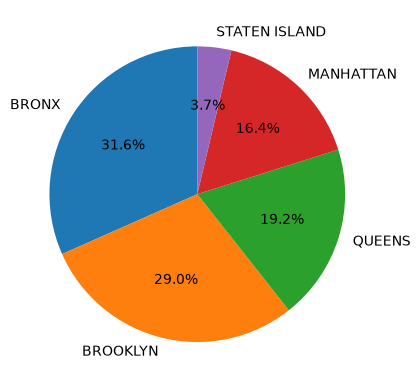

In [42]:
plt.pie(
    ranked_boroughs["count"], 
    labels=ranked_boroughs["BOROUGH"], 
    autopct="%1.1f%%",
    startangle=90
)


##### Multiple charts

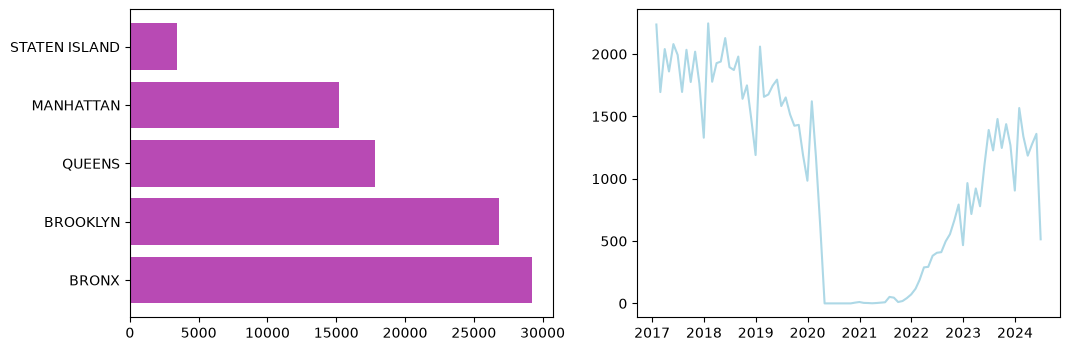

In [ ]:
# Fig is the entire blank canvas or window. 
# It controls global properties like the overall image size (figsize), background colors, and saving the final image file
# This is the actual plot or subplot drawn onto the canvas. I

fig,ax =  plt.subplots(1,2)

fig.set_size_inches(12,4)


ax[0].barh(ranked_boroughs["BOROUGH"],ranked_boroughs["count"], color = '#b84ab4')
ax[1].plot(evictions_tally, color='lightblue')


#### Saving your charts

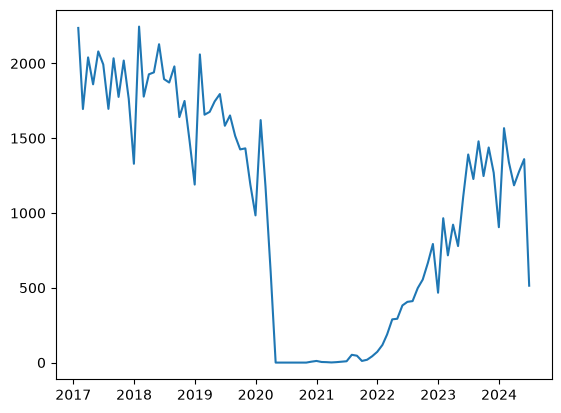

In [23]:
plt.plot(evictions_tally)
plt.savefig('../output/chart.svg')
plt.savefig('../output/chart.png')